[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_venues/BA_L1_venues.ipynb)

# BA_L1_venues: Trading on Centralised and Decentralised Exchanges

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Monthly spot volume of ten large centralised exchanges and of all decentralised exchanges, in USD, 24 November 2025 to 22 November 2026, and the share of decentralised exchanges in the sum.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

A centralised exchange records trades in its own ledger; a decentralised exchange executes them on a chain. The file
holds the daily spot volume in USD of ten large centralised exchanges and of all decentralised exchanges together.
The share of decentralised exchanges is $V^{DEX} / (V^{DEX} + V^{CEX})$ on monthly sums of full months.

**How to read the chart.** The volumes are reported by the venues and not audited. Only ten centralised exchanges
are counted, so the share on the right is an upper bound.

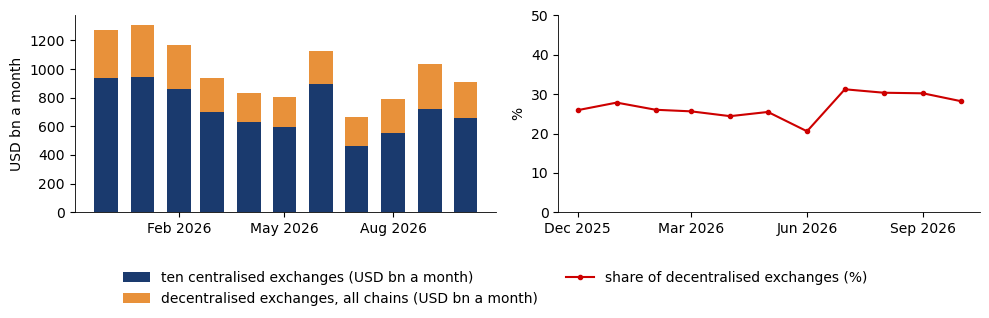

364 days, 24 November 2025 to 22 November 2026
Mean volume a day: ten centralised exchanges 23.8 USD bn, decentralised exchanges 8.7 USD bn
Share of decentralised exchanges in the sum: 26.7%; by full month from 20.6% to 31.2%
Largest centralised exchange: Binance, 38.7% of the ten


In [5]:
# daily spot volume (USD): ten large centralised exchanges (CoinGecko) and all decentralised exchanges (DefiLlama)
ev = pd.read_csv(data_file('market', 'exchange_volumes_daily.csv'), parse_dates=['date']).set_index('date')
dex = ev['DEX (all chains)']
cex = ev.drop(columns='DEX (all chains)')
both = pd.DataFrame({'cex': cex.sum(axis=1, min_count=8), 'dex': dex}).dropna()
mon = both.resample('MS').sum().iloc[1:-1] / 1e9                     # full months
share = 100 * mon['dex'] / (mon['dex'] + mon['cex'])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(mon.index, mon['cex'], width=20, color=BLUE, label='ten centralised exchanges (USD bn a month)')
ax[0].bar(mon.index, mon['dex'], width=20, bottom=mon['cex'], color=BTC, label='decentralised exchanges, all chains (USD bn a month)')
ax[0].set_ylabel('USD bn a month')
ax[1].plot(share.index, share.values, color=RED, marker='o', ms=3, label='share of decentralised exchanges (%)')
ax[1].set_ylabel('%'); ax[1].set_ylim(0, 50)
import matplotlib.dates as mdates
for a in ax:
    a.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
legend_below(fig, ncol=2, bottom=0.20)
save_fig(fig, 'ba_l1_venues')

tot = both.sum()
print(f'{len(both)} days, {both.index[0]:%d %B %Y} to {both.index[-1]:%d %B %Y}')
print(f'Mean volume a day: ten centralised exchanges {both["cex"].mean() / 1e9:.1f} USD bn, decentralised exchanges {both["dex"].mean() / 1e9:.1f} USD bn')
print(f'Share of decentralised exchanges in the sum: {100 * tot["dex"] / tot.sum():.1f}%; by full month from {share.min():.1f}% to {share.max():.1f}%')
print(f'Largest centralised exchange: {cex.sum().idxmax()}, {100 * cex.sum().max() / cex.sum().sum():.1f}% of the ten')